We will create the effect of chromatic aberration on high-quality image

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [5]:
def chromatic_aberration(image, strength=8, angle_deg=0):
    h, w = image.shape[:2]
    theta = np.deg2rad(angle_deg)
    dx, dy = strength * np.cos(theta), strength * np.sin(theta)
    channels = cv2.split(image)
    shifts = [(-dx, -dy), (0, 0), (dx, dy)]
    warped = []
    for ch, (tx, ty) in zip(channels, shifts):
        M = np.float32([[1, 0, tx], [0, 1, ty]])
        warped.append(cv2.warpAffine(ch, M, (w, h), borderMode=cv2.BORDER_REPLICATE))
    return cv2.merge(warped)

In [8]:
def load_image(image_path: str):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")
    return img

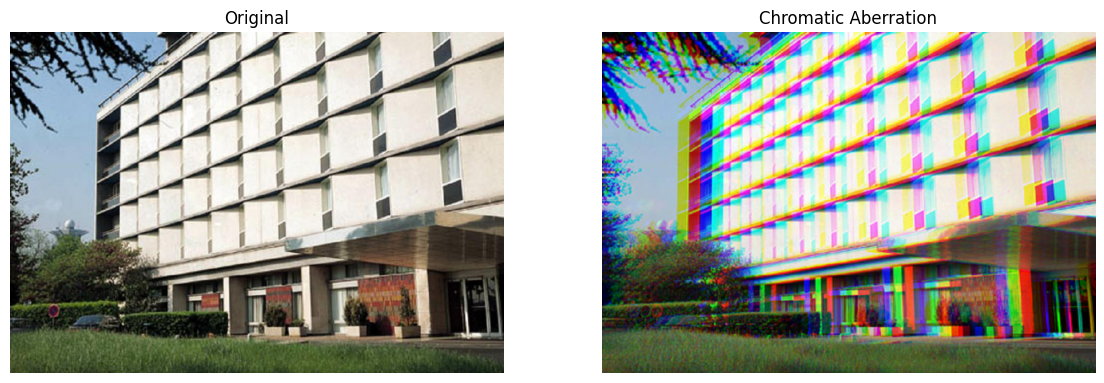

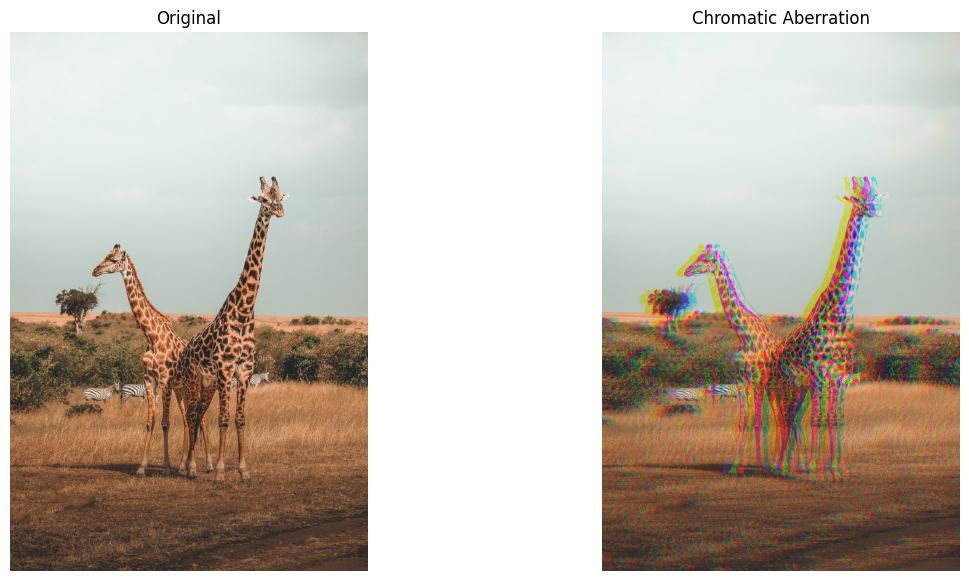

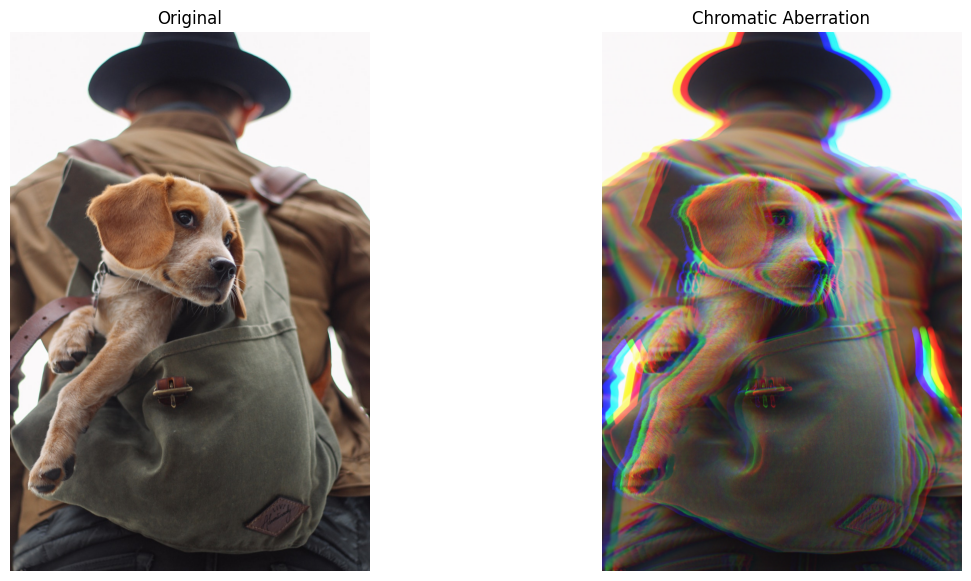

In [12]:
img_paths = ['building.jpg', 'giraffes.jpg', 'dog_backpack.jpg']
for img_path in img_paths:
  img = load_image(img_path)
  result = chromatic_aberration(
      img,
      strength=20,
      angle_deg=0,
  )

  fig, axes = plt.subplots(1, 2, figsize=(14, 7))
  axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  axes[0].set_title("Original")
  axes[0].axis("off")
  axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
  axes[1].set_title("Chromatic Aberration")
  axes[1].axis("off")
  plt.show()